# Analysis of Atmospheric River Mobility Data
The goal of this notebook is to perform an analysis of daily cell-phone trajectory statistics for the 30 March 2024 Atmospheric River event in southern California.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm
from scipy.stats import ks_2samp, bootstrap, ecdf, percentileofscore
from scipy.ndimage import gaussian_filter
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, LogNorm
import shapefile
import json
import urllib3
import xarray as xr
%matplotlib inline

## Data Loading
We will load data from our analysis pipeline and mapping data to aid in visualizing different aggregations of the statistics.
First we will load home locations estimated from the full trajectory data.

In [3]:
home_loc_df = pd.read_parquet("/glade/work/ggantos/cat-rain/notebooks/home_loc_by_row_group_counties_unfiltered.parquet")


In [6]:
home_loc_df

,duration,lat,lng,zipcode,row_group,county
uid,,,,,,
0000d7e8f39b8c01b42c30e0e8ff15c79e9fd0ea4204a08d4980931528fa5f33,0 days 23:54:20,33.993080,-118.454964,90291,0,LA
0000d5706648bfddd64ea083ea418ee3804ab9a3a89ed4a23138ddce3ddd9f54,2 days 09:09:58,34.157609,-118.267499,91203,0,LA
0000d52321518172e10971219b04d425f9205ad4f4aa5497dbddb2717d993be9,7 days 01:50:25,33.979911,-118.395343,90045,0,LA
0000d4b669bf0eefc20c4acea6e9d5cd0fee30fc7d02e09057eaf258cd30810f,0 days 06:51:00,34.140282,-118.240982,91205,0,LA
0000d3f70d721e99161e7f39154bff9d4319a53f6baad7eedc7ff6e7869361d4,4 days 23:15:49,34.107017,-118.200225,90042,0,LA
...,...,...,...,...,...,...
ffff7088806db769ebeb853db20fff3b8c5adc0ba8187f15319ff8191616aff3,0 days 19:42:00,34.171200,-118.518600,91316,75017,LA
ffff6f8e86528bc64ac8b3ae3721c68ceef8bf0b5e351e51a274c32916dcc66a,0 days 22:56:16,34.367467,-118.507601,91321,75017,LA
ffff6b6349c88e8316613fa99b4f9cdd205e23c26ddce21a46abcdaa62c7fcf6,1 days 00:01:19,34.192799,-118.488602,91406,75017,LA


In [165]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_file_dates = [ar_file.split("/")[-1].split("_")[1] for ar_file in ar_files]
all_dates = pd.DatetimeIndex(ar_file_dates)
sat_ids = np.where((all_dates.dayofweek == 5) & (all_dates.year == 2024))[0][:-2]
sat_datetimes = all_dates[sat_ids]
sat_dates = sat_datetimes.strftime("%Y-%m-%d")
print(sat_dates)
print(sat_ids)

Index(['2024-03-16', '2024-03-23', '2024-03-30', '2024-04-06', '2024-04-13'], dtype='object')
[47 54 61 68 75]


In [166]:
# Load county shape file
county_shapes = shapefile.Reader("/glade/campaign/cisl/aiml/cat_flood/ancillary_data/county_shapes/county_shapes").shapes()
# Load zip code shapes
with open("/glade/work/cbecker/california_zip.geojson") as cal_zip_file:
    cal_zips = json.load(cal_zip_file)
zip_codes = np.array([cz["properties"]["ZIP_CODE"] for cz in cal_zips["features"]])
# Load Flash Flood Warning Polygons
req = urllib3.request("GET", "https://mesonet.agron.iastate.edu/api/1/cow.json?wfo=LOX&begints=2024-03-28T12:00:00Z&enable_shared_border=1&endts=2024-03-31T12:00:00Z&hailsize=1&wind=58&phenomena=FF&lsrbuffer=15&warningbuffer=1")
ffws = json.loads(req.data)
rain_ds = xr.open_dataset("/glade/campaign/cisl/aiml/cat_flood/mrms/raw/mrms_precip_daily.nc")
rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30").max() / 25.4

<xarray.DataArray 'MultiSensor_QPE_01H_Pass2_00.00_sum' ()> Size: 8B
array(4.93700787)
Coordinates:
    time     datetime64[ns] 8B 2024-03-30
Attributes:
    Discipline:   209
    Category:     6.0
    Parameter:    37.0
    Name:         MultiSensor_QPE_01H_Pass2
    Frequency:    60-min
    Unit:         mm
    Missing:      -1.0
    No Coverage:  -3.0
    Description:  Multi-sensor accumulation 1-hour (2-hour latency)

In [287]:
ffws

{'generated_at': '2026-03-20T20:19:42Z',
 'params': {'wfo': ['LOX'],
  'phenomena': ['FF'],
  'lsrtype': ['TO', 'SV', 'FF', 'MA', 'DS', 'SQ'],
  'hailsize': 1.0,
  'lsrbuffer': 15.0,
  'wind': 58.0,
  'windhailtag': False,
  'limitwarns': False,
  'begints': '2024-03-28T12:00:00Z',
  'endts': '2024-03-31T12:00:00Z',
  'warningbuffer': 1.0,
  'enable_shared_border': True},
 'stats': {'area_verify[%]': 23.938217039134106,
  'shared_border[%]': 0.0,
  'max_leadtime[min]': 152,
  'min_leadtime[min]': 7,
  'avg_leadtime[min]': 63.2,
  'avg_leadtime_firstreport[min]': 47.0,
  'tdq_stormreports': 0,
  'unwarned_reports': 8,
  'warned_reports': 5,
  'events_verified': 2,
  'events_total': 4,
  'reports_total': 13,
  'POD[1]': 0.38461538461538464,
  'FAR[1]': 0.5,
  'CSI[1]': 0.2777777777777778,
  'avg_size[sq km]': 1134.1640807386348,
  'size_poly_vs_county[%]': 14.178373431498633,
  'svr_with_torpossible_total': 0,
  'svr_with_torpossible_verified': 0},
 'events': {'type': 'FeatureCollection'

In [167]:
ar_files = sorted(glob("/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121/veraset_*.parquet"))
ar_files = list(np.array(ar_files)[sat_ids])
ar_file = ar_files[0]
ar_date = ar_file.split("/")[-1].split("_")[1]
metric = 'distance_straight_line'
meta_cols = ["uid", "duration",	"lat_home",	"lng_home", "zipcode", "row_group",	"county"]
cols =  meta_cols + [metric]
df_0 = pd.read_parquet(ar_file, columns=cols)
df_0 = df_0.set_index("uid")
df_joined = df_0
new_col = ar_date
df_joined = df_joined.rename(columns={metric: new_col})
metric_cols = [new_col]
for ar_file in tqdm(ar_files[1:]):
    ar_date = ar_file.split("/")[-1].split("_")[1]
    df_l = pd.read_parquet(ar_file, columns=cols)
    df_l = df_l.set_index("uid")
    df_joined = df_joined.join(df_l.loc[:, [metric]], how="outer")
    new_rows = df_joined.index[np.isnan(df_joined["lat_home"])]

    df_joined.loc[new_rows, meta_cols[1:]] = df_l.loc[new_rows, meta_cols[1:]]
    new_col = f"{ar_date}"
    df_joined = df_joined.rename(columns={metric: f"{ar_date}"})
    metric_cols.append(new_col)

100%|██████████| 4/4 [00:23<00:00,  5.86s/it]


Now that data are loaded, we filter out people who do not have a distance traveled statistic for all Saturdays in our analysis.

In [200]:
df_joined_sub = df_joined.dropna()

In [202]:
m_date = "2024-03-30"
daily_ar_data = pd.read_parquet(f'/glade/campaign/cisl/aiml/cat_flood/analysis_ready_data_20251121_mrms/veraset_{m_date}_PST_chunked.parquet')
daily_ar_data = daily_ar_data.set_index("uid")
ar_cols = ["num_stops", "number_of_visits", "FFW", "precip_max", "precip_sum", "streamflow_max", "streamflow_sum"]
df_joined_ar = df_joined_sub.join(daily_ar_data[ar_cols])

<Axes: >

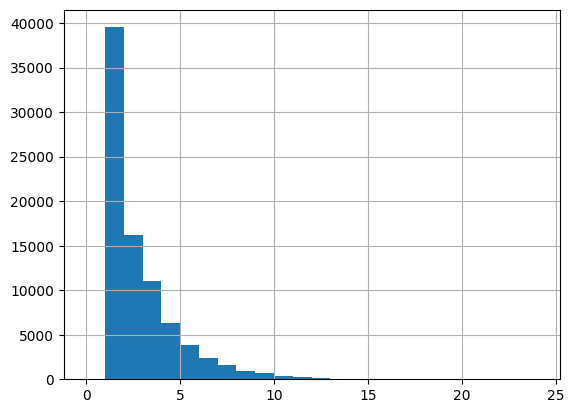

In [205]:
df_joined_ar["num_stops"].hist(bins=np.arange(25))


## Statistical Calculations
Travel patterns vary significantly from person to person. To control for this variation, we calculate the percentile of the total distance traveled for the Saturday of the AR event relative to the 2 Saturdays before and the 2 Saturdays after. While we have acquired more data than these Saturdays, our dataset contains fewer contiguous records of paired daily cell phone trajectories as the time window is expanded. We have to trade off sample size for data fidelity.

In [233]:
metric_array = df_joined_ar[metric_cols].values.astype(np.float64)
user_ar_percentile = np.zeros(df_joined_ar.shape[0])
for i in tqdm(range(metric_array.shape[0])):
    user_ar_percentile[i] = percentileofscore(metric_array[i, [True, True, False, True, True]], 
                                              metric_array[i, 2], nan_policy="omit")
df_joined_ar[metric + "_percentile"] = user_ar_percentile

100%|██████████| 83503/83503 [00:03<00:00, 22786.66it/s]


(array([23837., 16531., 14182., 14711., 14242.]),
 array([  0.,  20.,  40.,  60.,  80., 100.]),
 <BarContainer object of 5 artists>)

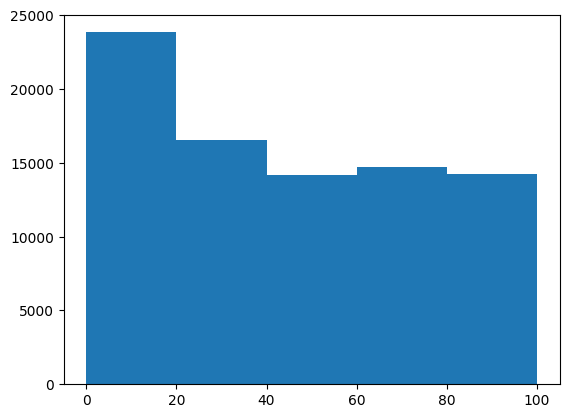

In [210]:
plt.hist(user_ar_percentile, bins=np.arange(0, 120,20))


(array([0.01423256, 0.00988935, 0.00849746, 0.00880233, 0.0085783 ]),
 array([  0.,  20.,  40.,  60.,  80., 100.]),
 [<matplotlib.patches.Polygon at 0x14fd6ad47350>])

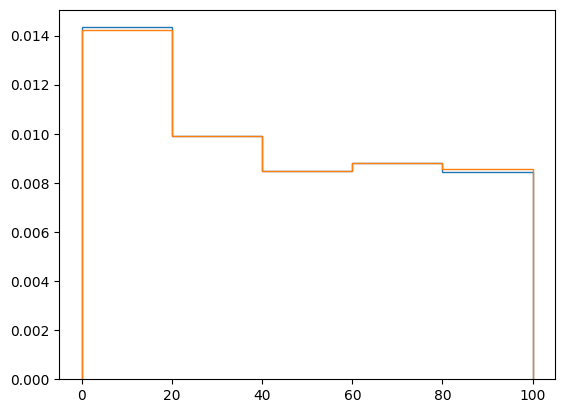

In [237]:
plt.hist(df_joined_ar.loc[df_joined_ar["FFW"], metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True)
plt.hist(df_joined_ar.loc[~df_joined_ar["FFW"], metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True)

(array([0.01438787, 0.00973438, 0.00848553, 0.00893795, 0.00845426]),
 array([  0.,  20.,  40.,  60.,  80., 100.]),
 [<matplotlib.patches.Polygon at 0x14fe78bad2d0>])

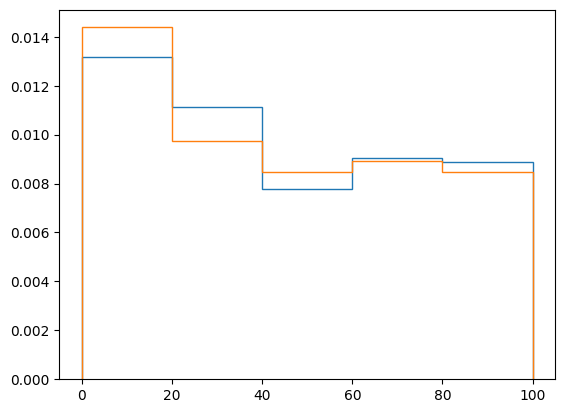

In [248]:
pos_idx =  (df_joined_ar["precip_sum"] >= 50) & (df_joined_ar["county"] == "LA")
neg_idx =  (df_joined_ar["precip_sum"] < 35) & (df_joined_ar["county"] == "LA")
plt.hist(df_joined_ar.loc[pos_idx, metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True, cumulative=False)
plt.hist(df_joined_ar.loc[neg_idx, metric + "_percentile"], np.arange(0, 120, 20), histtype="step", density=True, cumulative=False)

In [249]:
ks_2samp(df_joined_ar.loc[pos_idx, metric + "_percentile"],df_joined_ar.loc[neg_idx, metric + "_percentile"]) 

KstestResult(statistic=np.float64(0.024243971266738384), pvalue=np.float64(0.8777322039400764), statistic_location=np.float64(0.0), statistic_sign=np.int8(-1))

In [250]:
ranks = np.argsort(metric_array, axis=1)

(array([23838., 16529., 14194., 14700., 14242.]),
 array([0., 1., 2., 3., 4., 5.]),
 <BarContainer object of 5 artists>)

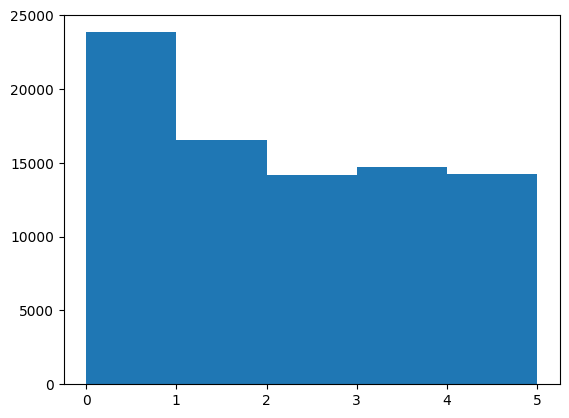

In [262]:
plt.hist(np.where(ranks==2)[1], np.arange(6))

In [267]:
ks_2samp(np.where(ranks==2)[1], np.where(ranks==0)[1])

KstestResult(statistic=np.float64(0.22929715100056286), pvalue=np.float64(0.0), statistic_location=np.int64(1), statistic_sign=np.int8(1))

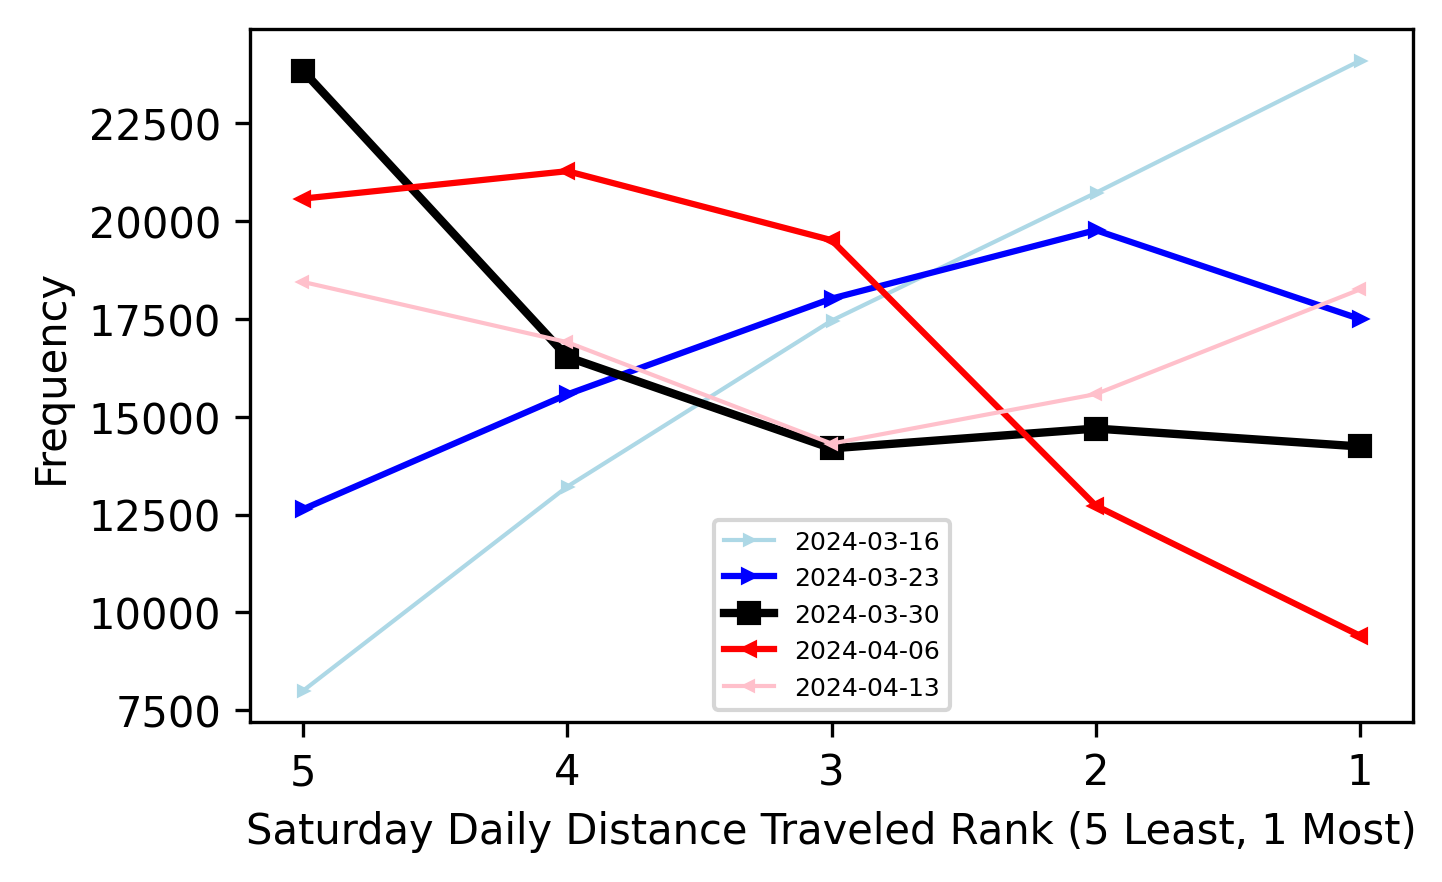

In [297]:
plt.figure(figsize=(5, 3), dpi=300)
color = ["lightblue", "blue", "k", "red", "pink"]
marker = [">", ">", "s", "<", "<"]
marker_size = [2, 3, 5, 3, 2]
linewidth = [1, 1.5, 2, 1.5, 1]
bins = np.arange(1, 7)
for i in range(ranks.shape[1]):
    hist_out, _ = np.histogram(np.where(ranks == i)[1] + 1, bins=bins)
    plt.plot(bins[:-1], hist_out, 
             color=color[i], 
             marker=marker[i], 
             ms=marker_size[i], 
             lw=linewidth[i],
             label=sat_dates[i])
plt.xticks(np.arange(1, 6), np.arange(1, 6)[::-1])
plt.xlabel("Saturday Daily Distance Traveled Rank (5 Least, 1 Most)")
plt.ylabel("Frequency")
plt.legend(fontsize=6)
plt.savefig("travel_freq.png", dpi=300, bbox_inches="tight")
plt.savefig("travel_freq.pdf", dpi=300, bbox_inches="tight")

## Maps

In [225]:
zip_traces = pd.DataFrame(0.0, index=zip_counts.index, columns=[metric + "_percentile"])
for zip_code in zip_counts.index:
    zip_traces.loc[zip_code] = np.mean(df_joined_ar.loc[df_joined_ar["zipcode"] == zip_code, metric + "_percentile"], axis=0)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


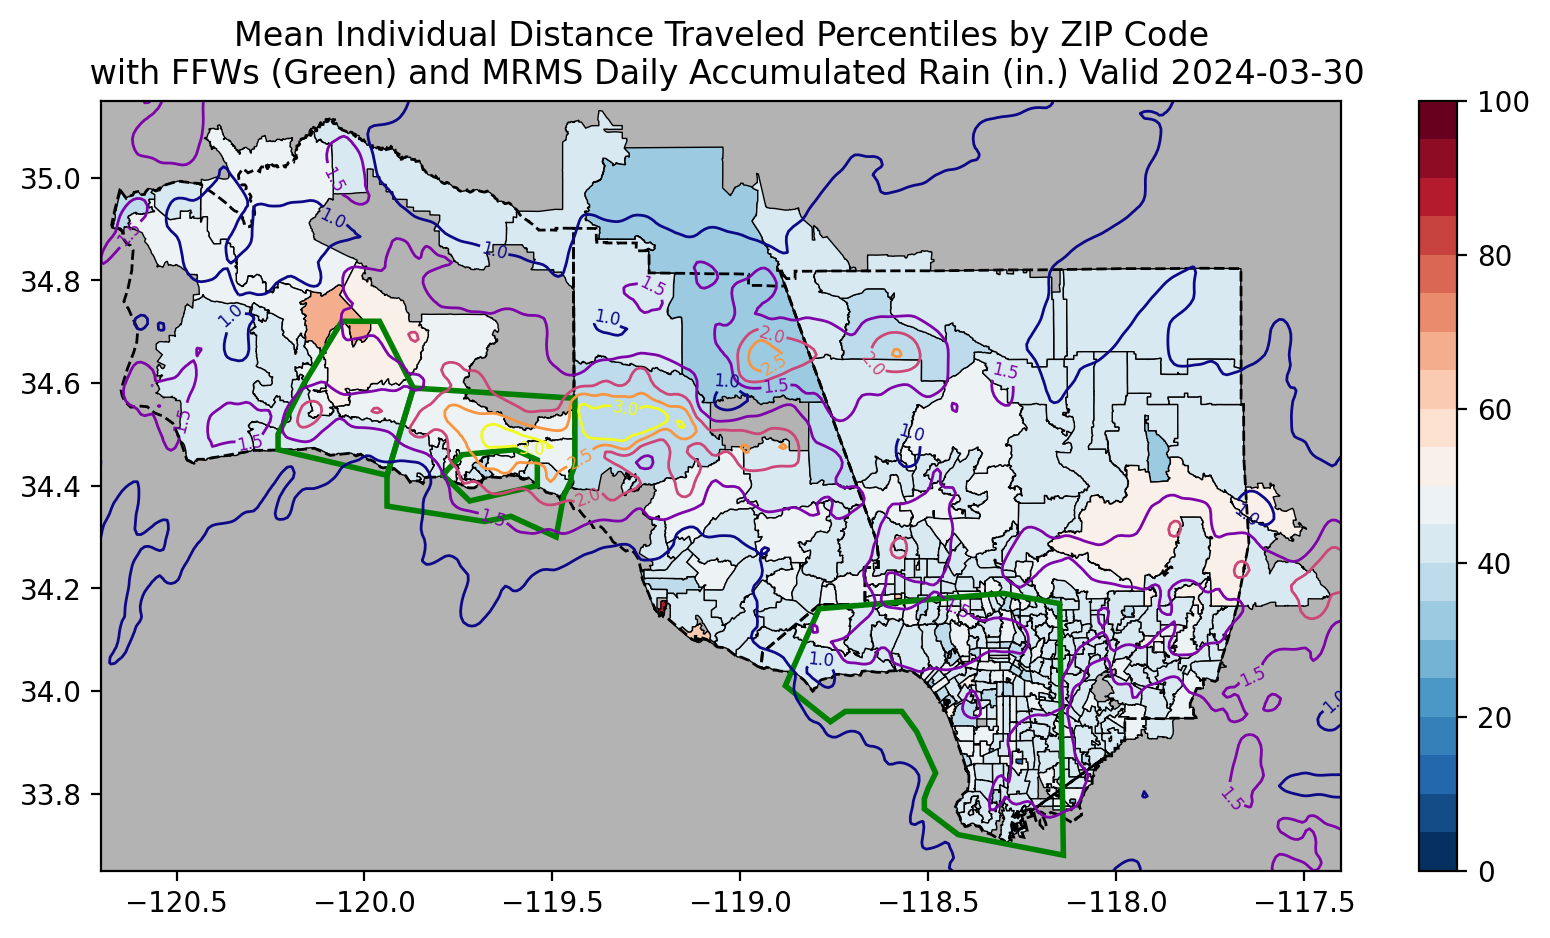

In [310]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-120.7, -117.4)
plt.ylim(33.65, 35.15)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


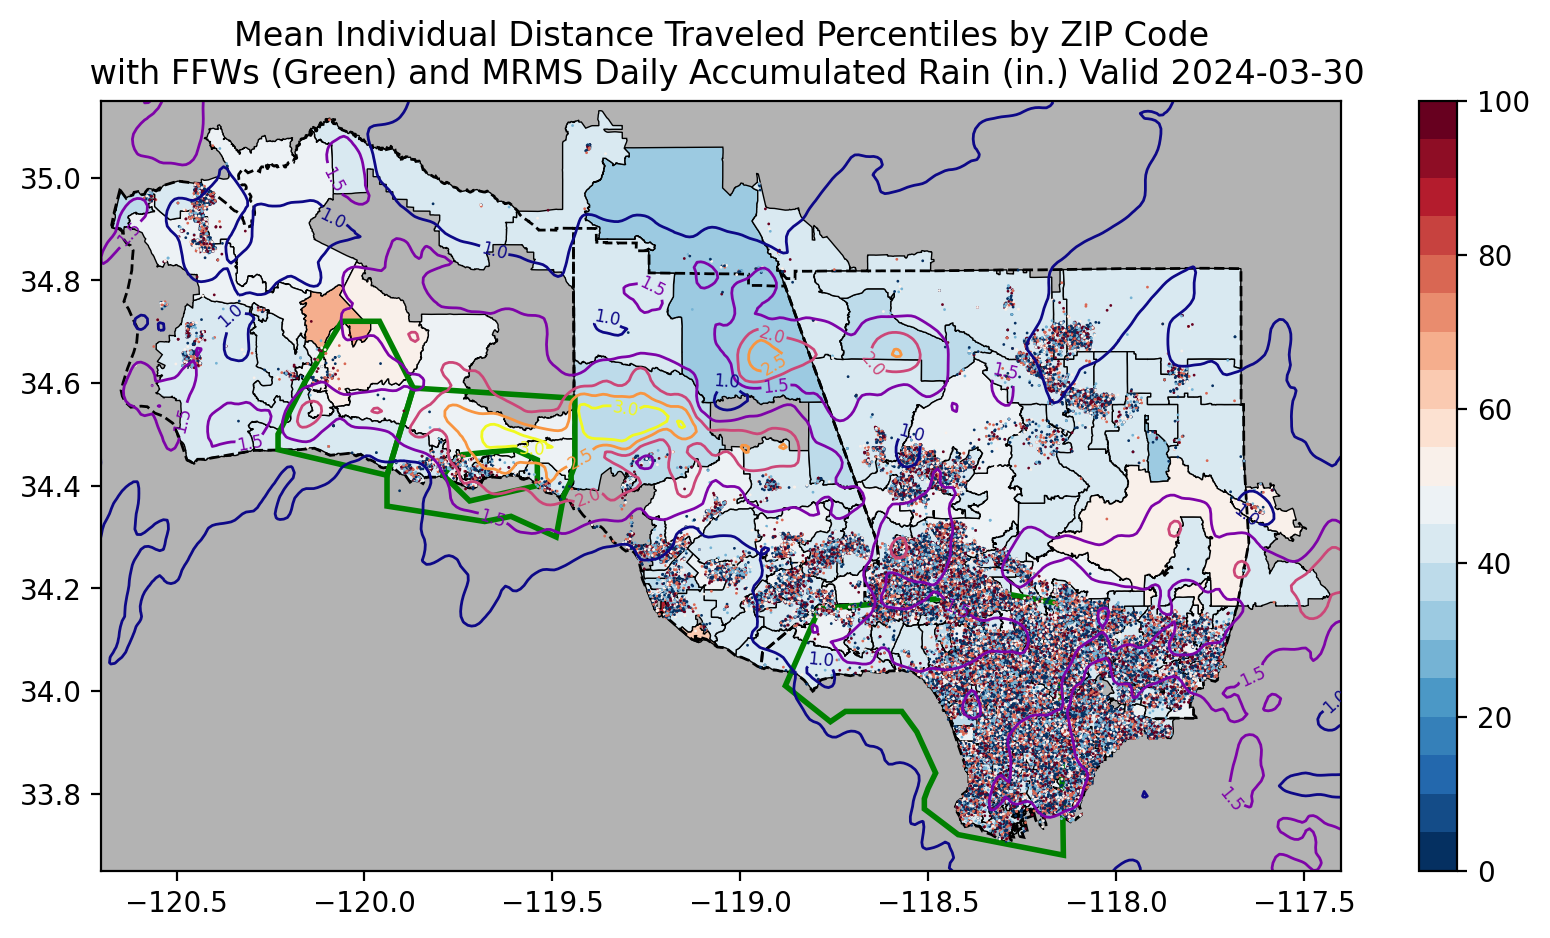

In [309]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-120.7, -117.4)
plt.ylim(33.65, 35.15)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.scatter(df_joined_ar["lng_home"], df_joined_ar["lat_home"], 1, df_joined_ar[metric + "_percentile"], cmap=cmap, vmin=0, vmax=100, ec="none")
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_users.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


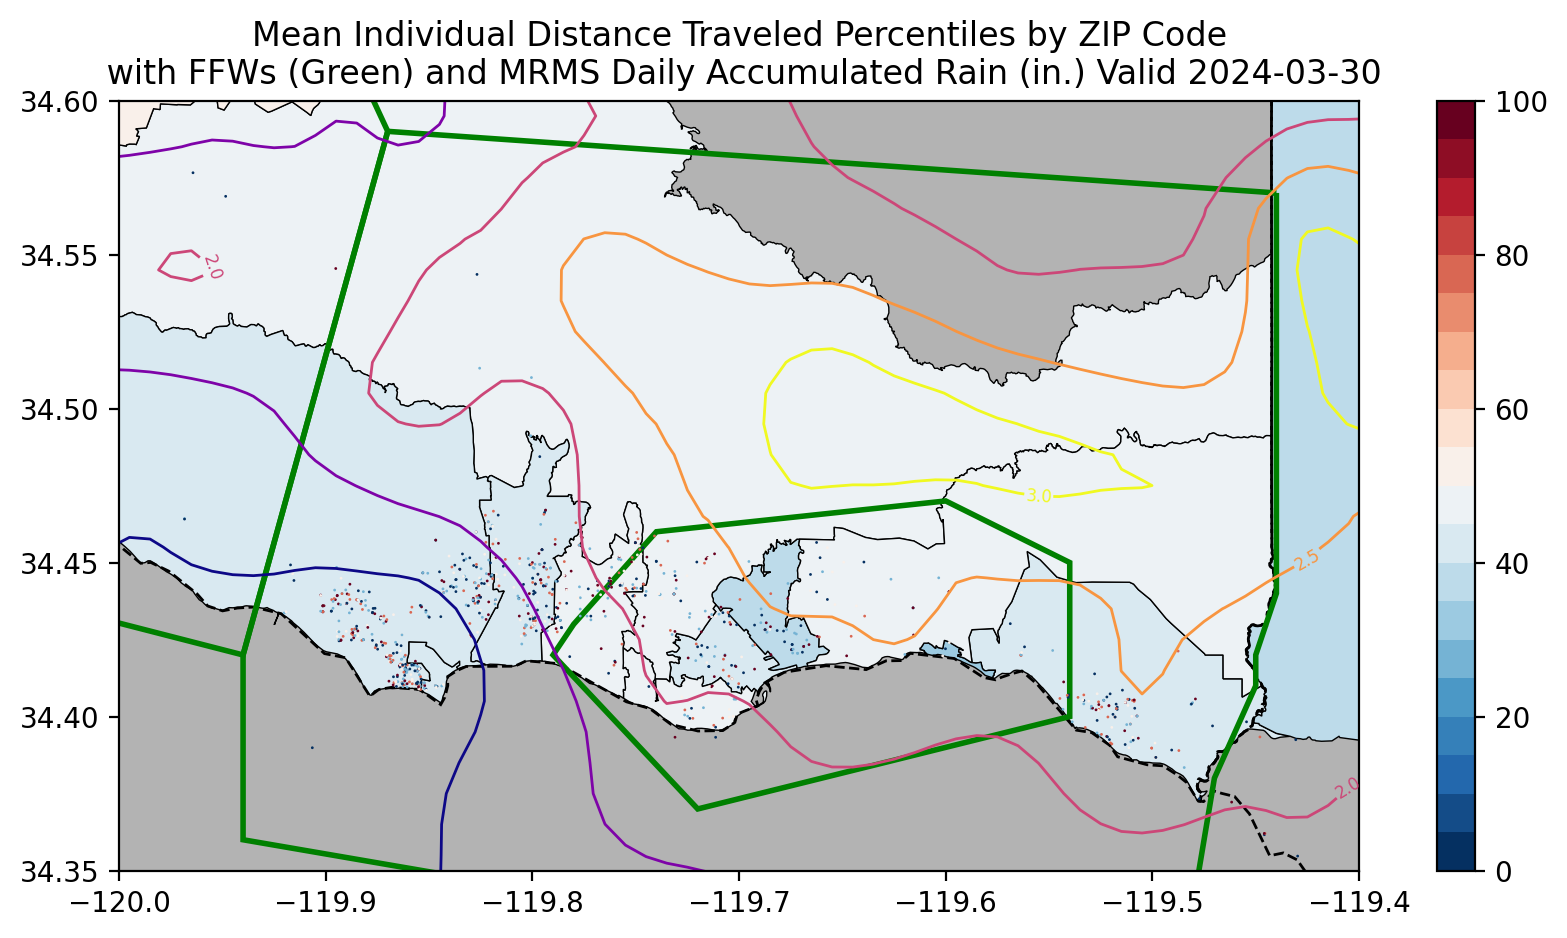

In [312]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-120.0, -119.4)
plt.ylim(34.35, 34.6)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.scatter(df_joined_ar["lng_home"], df_joined_ar["lat_home"], 1, df_joined_ar[metric + "_percentile"], cmap=cmap, vmin=0, vmax=100, ec="none")
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_users_sb.png", bbox_inches="tight", dpi=300)

[-120.16   34.6 ]
[-119.44   34.57]
[-118.3    34.19]
[-119.78   34.43]


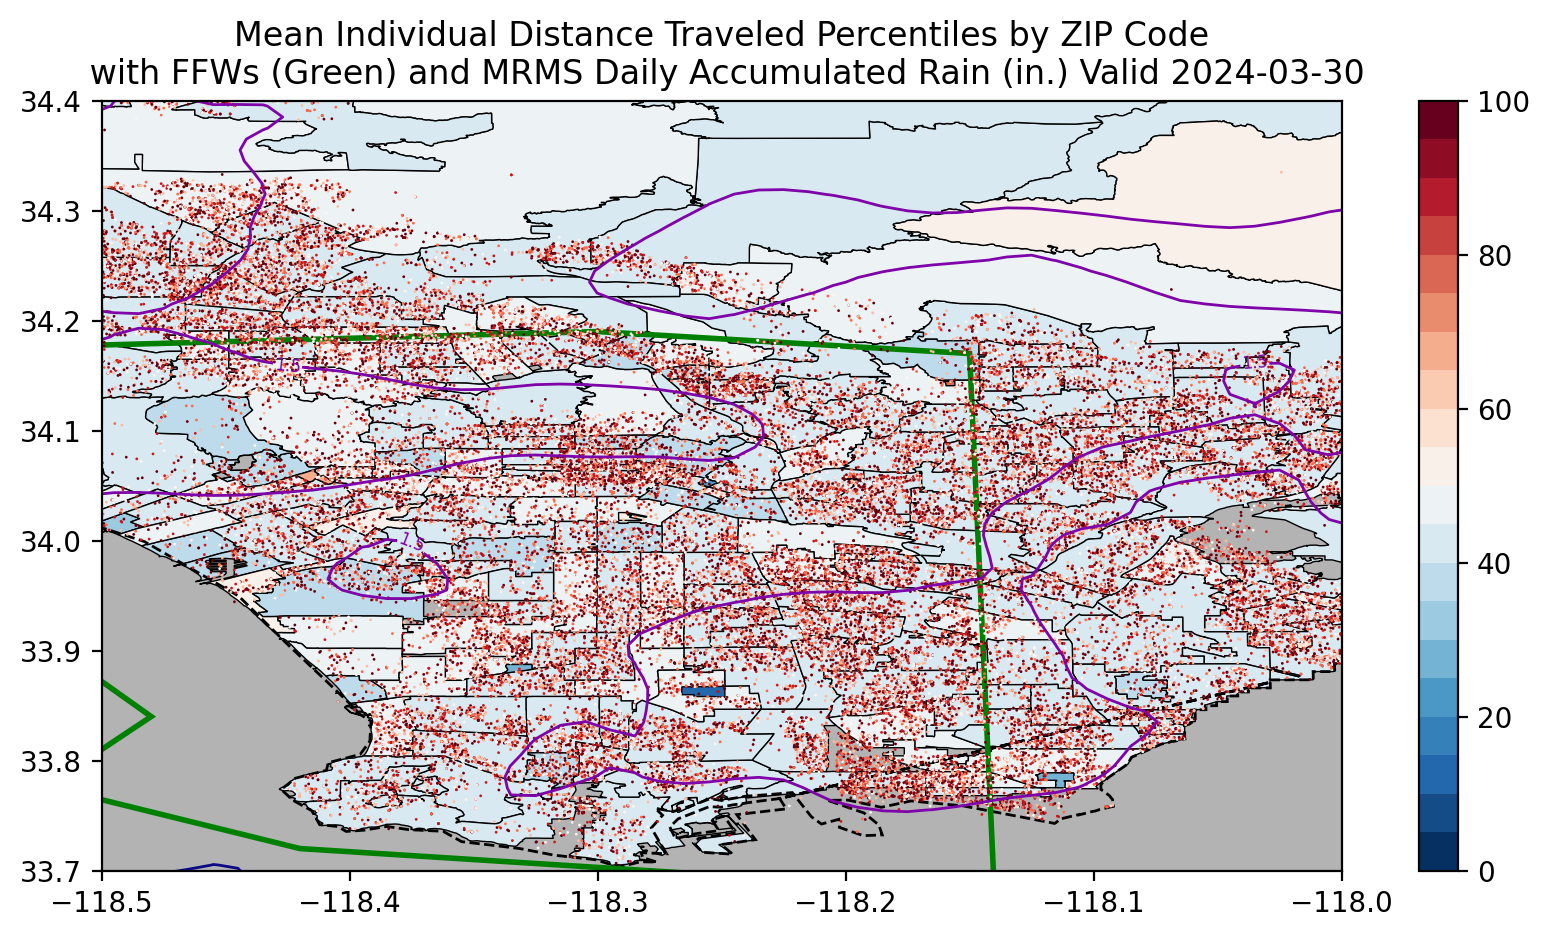

In [319]:
fig = plt.figure(figsize=(10, 5), dpi=200)
cmap = plt.get_cmap("RdBu_r", 20)
norm = Normalize(0, 100)
sm = ScalarMappable(norm=norm, cmap=cmap)

for i, zi in enumerate(zip_index):
    coords = np.array(cal_zips["features"][zi]["geometry"]["coordinates"][0])
    plt.fill(coords[:, 0], coords[:, 1], color=sm.to_rgba(zip_traces.iloc[i].loc[metric + "_percentile"]), ec='k', lw=0.5)
for county_shape in county_shapes:
    county_coords = np.array(county_shape.points).T
    plt.fill(county_coords[0], county_coords[1], facecolor="none", edgecolor="k", linestyle="--")
plt.xlim(-118.5, -118.0)
plt.ylim(33.7, 34.4)
for ffw in ffws["events"]["features"]:
    coords = np.array(ffw["geometry"]["coordinates"][0][0])
    print(coords[0])
    plt.fill(coords[:, 0], coords[:, 1], edgecolor='g', facecolor="none", lw=2)
rain_cont = plt.contour(rain_ds["lon"] - 360, rain_ds["lat"], gaussian_filter(rain_ds["MultiSensor_QPE_01H_Pass2_00.00_sum"].sel(time="2024-03-30") / 25.4, 1), 
            [1.0, 1.5, 2, 2.5, 3], cmap="plasma", linewidths=1.0)
plt.clabel(rain_cont, fontsize=6)
plt.scatter(df_joined_ar["lng_home"], df_joined_ar["lat_home"], 1, df_joined_ar[metric + "_percentile"], cmap="Reds_r", vmin=0, vmax=100, ec="none")
plt.gca().set_facecolor("0.7")
plt.colorbar(sm, ax=plt.gca())
plt.title("Mean Individual Distance Traveled Percentiles by ZIP Code\n with FFWs (Green) and MRMS Daily Accumulated Rain (in.) Valid 2024-03-30")
plt.savefig("zscore_zip_code_sat_users_la.png", bbox_inches="tight", dpi=300)